# TECH2 term paper (H26)

## Boom, slump, recovery? Green energy innovation in European patent data

**Candidate numbers:** 101, 133

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

***
## Task 1: Import and prepare the data

Each file is read inside its own function, which keeps only the columns and rows we need.
The full file therefore only exists in memory while the function runs.
Task 1 leaves four objects that Tasks 2–5 reuse without reading any file again:

| Object | One row per | Columns |
|---|---|---|
| `patents` | sample patent (priority year 2000–2019) | `appln_id`, `prio_year` |
| `green` | Y02E code of a green patent | `appln_id`, `prio_year`, `main_group`, `technology` |
| `applicants` | (sample patent, applicant) | `appln_id`, `app_name`, `ctry_code`, `app_share` |
| `categories` | (green patent, main group or technology), built from `green` | `appln_id`, `prio_year`, `category` |

We first define the file location, the sample period and the labels from Tables 1 and 2.

In [2]:
# Relative path: the data folder sits next to the notebook
DATA_PATH = 'data'

# Sample: priority years from FIRST_YEAR to LAST_YEAR (inclusive)
FIRST_YEAR = 2000
LAST_YEAR = 2019

# Smaller integer types for the id and year columns, used when reading all
# three files, so the ids have the same type when the tables are merged
ID_TYPES = {'appln_id': 'int32', 'prio_year': 'int16'}

# Table 1: main group (two digits before the slash) -> label
MAIN_GROUPS = {
    '10': 'Renewable energy',
    '20': 'Efficient combustion',
    '30': 'Nuclear energy',
    '40': 'Efficient power transmission',
    '50': 'Non-fossil fuels',
    '60': 'Storage and hydrogen',
    '70': 'Other energy conversion',
}

# One colour per main group, keyed by label and used in all figures. In
# Table 1 order, neighbouring segments of the Task 3 stacked bars are easy to
# tell apart, also for colour-blind readers
COLORS = {
    'Renewable energy': '#2a78d6',
    'Efficient combustion': '#eb6834',
    'Nuclear energy': '#1baf7a',
    'Efficient power transmission': '#eda100',
    'Non-fossil fuels': '#e87ba4',
    'Storage and hydrogen': '#008300',
    'Other energy conversion': '#6250d6',
}

# Table 2: first digit after the slash in main group 10 -> technology.
# Digits not listed (e.g. 10/0...) belong to no technology.
TECHNOLOGIES = {
    '1': 'Other renewables',
    '2': 'Other renewables',
    '3': 'Other renewables',
    '4': 'Solar',
    '5': 'Solar',
    '6': 'Solar',
    '7': 'Wind',
}

# One colour per technology, keyed by name, so a technology keeps its colour
# whatever the sort order (Tasks 4 and 5)
TECH_COLORS = {'Solar': '#2a78d6', 'Wind': '#eb6834', 'Other renewables': '#1baf7a'}

### Sample patents

The IPC file has one row per IPC code, so a patent appears on several rows.
We read only the patent id and priority year, keep the sample years and reduce to one row per patent.
Both columns are read as smaller integer types, which halves the memory of the full read; with only two numeric columns the full read stays small, so we don't need chunks here.

In [3]:
def read_patents(file='202608_EPO_IPC.txt'):
    """
    Read the sample of EPO patent applications.

    Parameters
    ----------
    file : str
        Name of the IPC file in ``DATA_PATH``.

    Returns
    -------
    pandas.DataFrame
        One row per sample patent, with columns ``appln_id`` and ``prio_year``.
    """
    # Two integer columns only: skipping the IPC code strings saves most memory.
    # dtype= stores them in fewer bytes than the default int64: ids go up to
    # about 640 million (fits int32) and years fit int16. That is 6 instead of
    # 16 bytes per row, so the full read of 19.7 million rows needs no chunks
    df = pd.read_csv(
        f'{DATA_PATH}/{file}',
        sep='|',
        usecols=['appln_id', 'prio_year'],
        dtype=ID_TYPES,
    )

    # Keep the sample period
    df = df.loc[(df['prio_year'] >= FIRST_YEAR) & (df['prio_year'] <= LAST_YEAR)]

    # drop_duplicates() removes repeated identical rows: the same patent was
    # listed once per IPC code, and we want one row per patent
    df = df.drop_duplicates(ignore_index=True)

    return df

### Green energy patents

The CPC file is the largest (35.6 million rows), but only a small fraction are `Y02E` codes.
We read it in chunks of one million rows and keep only the `Y02E` rows from each chunk.
This needs about 0.3 GB of memory instead of about 1.8 GB for reading the whole file at once, at the same speed.
The codes are padded with a varying number of spaces (e.g. `Y02E  10/72`), so we remove the spaces and read the main group and technology digit by position.

In [4]:
def read_green(patents, file='202608_CPC_Classes.txt', chunksize=1_000_000):
    """
    Read the Y02E codes of green energy patents in the sample.

    Parameters
    ----------
    patents : pandas.DataFrame
        Sample patents with columns ``appln_id`` and ``prio_year``.
    file : str
        Name of the CPC file in ``DATA_PATH``.
    chunksize : int
        Number of rows read at a time.

    Returns
    -------
    pandas.DataFrame
        One row per Y02E code of a green patent, with columns ``appln_id``,
        ``prio_year``, ``main_group`` and ``technology``.
    """
    # chunksize= makes read_csv() return the file in pieces of `chunksize` rows,
    # so only one piece is in memory while we filter it
    chunks = pd.read_csv(
        f'{DATA_PATH}/{file}',
        sep='|',
        usecols=['appln_id', 'CPC_Class'],
        dtype={'appln_id': ID_TYPES['appln_id']},
        chunksize=chunksize,
    )

    # Keep only Y02E rows from each piece; .str.startswith() checks the first
    # characters of each code
    parts = []
    for chunk in chunks:
        parts.append(chunk.loc[chunk['CPC_Class'].str.startswith('Y02E')])
    df = pd.concat(parts, ignore_index=True)
    del parts

    # .str.replace() removes the padding spaces, so every code has the fixed
    # layout 'Y02E10/72' and the digits sit at fixed positions
    df['code'] = df['CPC_Class'].str.replace(' ', '')
    df = df.drop(columns='CPC_Class')

    # .str[4:6] slices characters 4-5 (the main group); .map() looks each one
    # up in the dict and returns its Table 1 label
    group = df['code'].str[4:6]
    df['main_group'] = group.map(MAIN_GROUPS)

    # Technology exists only within main group 10: the first digit after the
    # slash (character 7). Digits not in Table 2 give a missing value.
    is_renewable = group == '10'
    df.loc[is_renewable, 'technology'] = (
        df.loc[is_renewable, 'code'].str[7].map(TECHNOLOGIES)
    )

    # The code text is not needed after this: each row still stands for one
    # Y02E code, and the labels carry everything Tasks 2-5 use
    df = df.drop(columns='code')

    # Inner merge keeps only sample patents and adds their priority year
    df = pd.merge(patents, df, on='appln_id', how='inner')

    return df

### Applicants

We read the four applicant columns in chunks of one million rows and keep the applicants of sample patents from each chunk, as for the CPC file.
The full file (5.1 million rows, about 0.7 GB as a DataFrame) is therefore never in memory at once; only one chunk is.
Namibia's country code is `NA`, which pandas reads as a missing value by default, so we tell it that only empty fields are missing.
Without the region columns, an applicant linked to several regions appears on identical rows, so we drop exact duplicates to avoid counting their share twice.
We do this after joining the chunks, so that duplicate rows that end up in different chunks are also caught.
Only after that do we upper-case the names, so that spelling variants of the same applicant are grouped together in Task 5.
Finally, names and country codes are stored as categories: each distinct name is kept once, and every row only holds a small number pointing to it. This cuts the memory of the table from about 430 MB to about 85 MB (printed below).

In [5]:
def read_applicants(patents, file='202608_EPO_App_reg.txt', chunksize=1_000_000):
    """
    Read the applicants of sample patents.

    Parameters
    ----------
    patents : pandas.DataFrame
        Sample patents with column ``appln_id``.
    file : str
        Name of the applicant file in ``DATA_PATH``.
    chunksize : int
        Number of rows read at a time.

    Returns
    -------
    pandas.DataFrame
        One row per (sample patent, applicant), with columns ``appln_id``,
        ``app_name`` (upper case), ``ctry_code`` and ``app_share``.
    """
    # The file starts with a byte-order mark (BOM); encoding='utf-8-sig'
    # strips it so the header line is read cleanly.
    # By default pandas reads the text 'NA' as a missing value, but here it is
    # Namibia's country code: keep_default_na=False switches that rule off,
    # and na_values=[''] keeps truly empty fields (e.g. empty names) missing.
    # chunksize= returns the file in pieces, as in read_green()
    chunks = pd.read_csv(
        f'{DATA_PATH}/{file}',
        sep='|',
        usecols=['appln_id', 'app_name', 'ctry_code', 'app_share'],
        dtype={'appln_id': ID_TYPES['appln_id']},
        encoding='utf-8-sig',
        keep_default_na=False,
        na_values=[''],
        chunksize=chunksize,
    )

    # Keep applicants of sample patents only, one piece at a time
    parts = []
    for chunk in chunks:
        parts.append(chunk.loc[chunk['appln_id'].isin(patents['appln_id'])])
    df = pd.concat(parts, ignore_index=True)
    del parts

    # Applicants with several regions appear on identical rows once the region
    # columns are left out; keep one so app_share is not counted twice.
    # Done after the concat, so duplicates that fall in different chunks are
    # also caught
    df = df.drop_duplicates(ignore_index=True)

    # .str.upper() unifies spelling such as 'Siemens AG' / 'SIEMENS AG'.
    # Done after deduplication so the step above is not affected.
    df['app_name'] = df['app_name'].str.upper()

    # The same names and country codes repeat on many rows. astype('category')
    # stores each distinct value once and gives every row a small integer code
    # instead of its own copy of the text, which saves most of the memory.
    # Done after the concat, so all chunks share one set of categories
    df['app_name'] = df['app_name'].astype('category')
    df['ctry_code'] = df['ctry_code'].astype('category')

    return df

### Import

We read each file once and report the size of the three objects.

In [6]:
# The only place in the notebook where files are read
patents = read_patents()
green = read_green(patents)
applicants = read_applicants(patents)

# Rows and memory per object; memory_usage(deep=True) also counts the text
for name, df in {'patents': patents, 'green': green, 'applicants': applicants}.items():
    size_mb = df.memory_usage(deep=True).sum() / 1e6
    print(f'{name:<11}{len(df):>11,} rows {size_mb:>8.1f} MB')

patents      2,835,599 rows     17.0 MB
green          141,882 rows     16.1 MB
applicants   3,059,537 rows     84.5 MB


### One row per patent and category

Tasks 3–5 count a patent once in each category it belongs to, where a category is a main group (Table 1) or a technology (Table 2).
We build this table once here, so the later tasks only select the labels they need and count rows.

In [7]:
# Stack the Table 1 labels (main_group) and the Table 2 labels (technology)
# into one 'category' column, so any label can be looked up the same way.
# Codes without a technology (NaN) are dropped from the technology part only,
# so Y02E 10/0... codes still count in main group 10 (Renewable energy).
categories = pd.concat(
    [
        green[['appln_id', 'prio_year', 'main_group']].rename(
            columns={'main_group': 'category'}
        ),
        green[['appln_id', 'prio_year', 'technology']]
        .rename(columns={'technology': 'category'})
        .dropna(),
    ],
    ignore_index=True,
)

# A patent with several codes in the same category must count once there.
# Done once here; Tasks 3-5 then count rows with .size()
categories = categories.drop_duplicates(ignore_index=True)
print(f'categories: {len(categories):,} rows (patent, category)')

categories: 162,166 rows (patent, category)


### Checkpoints

We compare our data with the three checkpoints in the exam text.
A green patent appears once per Y02E code in `green`, so we count distinct patent ids, not rows.

In [8]:
# .nunique() returns the number of distinct values in a column; reused below
# for the average number of codes per green patent
n_green = green['appln_id'].nunique()

# Our result next to the checkpoint from the exam text (for comparison only)
checkpoints = {
    'Sample patents': (len(patents), 2_835_599),
    'Green energy patents': (n_green, 114_924),
    'Sum of app_share': (round(applicants['app_share'].sum()), 2_835_140),
}
for name, (ours, exam) in checkpoints.items():
    status = '✓' if ours == exam else '✗'
    print(f'{name:<21}{ours:>11,}   exam: {exam:>11,}  {status}')

Sample patents         2,835,599   exam:   2,835,599  ✓
Green energy patents     114,924   exam:     114,924  ✓
Sum of app_share       2,835,140   exam:   2,835,140  ✓


### Overview of the data structure

A green patent can have several Y02E codes, and these codes can belong to different main groups.
A patent can also have several applicants, possibly from different countries.
For each patent we count its distinct main groups and distinct applicant countries.

In [9]:
# Every row of green is one Y02E code, so codes per patent = rows / patents
avg_codes = len(green) / n_green

# Distinct main groups per green patent; summing the True/False values
# counts the patents with more than one
groups_per_patent = green.groupby('appln_id')['main_group'].nunique()
n_multi_group = (groups_per_patent > 1).sum()

# Same idea for applicant countries per sample patent
countries_per_patent = applicants.groupby('appln_id')['ctry_code'].nunique()
n_multi_country = (countries_per_patent > 1).sum()

print(f'Average Y02E codes per green patent:       {avg_codes:.2f}')
print(f'Green patents in more than one main group: {n_multi_group:,}')
print(f'Sample patents with applicants in more than one country: {n_multi_country:,}')

Average Y02E codes per green patent:       1.23
Green patents in more than one main group: 4,359
Sample patents with applicants in more than one country: 58,955


On average, a green energy patent has 1.23 Y02E codes, 4,359 green patents belong to more than one main group, and 58,955 patents in the sample have applicants in more than one country.
This shows that the data is structured as one row per code and one row per applicant, not one row per patent.
The same patent can appear on several rows and belong to several categories at once.
In the later tasks we therefore count each patent only once per category, and use `app_share` to split patents between countries and applicants.
No country codes are missing: pandas reads Namibia's code "NA" as a missing value by default, so we read the applicant file with `keep_default_na=False`.

***
## Task 2: Has green energy patenting slumped?

### Patents per year

`green` has one row per Y02E code, so we count distinct patent ids per year. `patents` already has one row per patent, so there we count rows.
The share is green patents as a percentage of all sample patents in the same priority year.

In [10]:
# green has one row per Y02E code: count distinct patents, since .size()
# would count a patent with two codes twice
n_green_year = green.groupby('prio_year')['appln_id'].nunique()

# patents has one row per patent, so counting rows counts patents
n_total_year = patents.groupby('prio_year').size()

# A dict of Series becomes a DataFrame; the rows line up on the year index
by_year = pd.DataFrame({'green': n_green_year, 'total': n_total_year})
by_year['share'] = by_year['green'] / by_year['total'] * 100

# Each patent has one priority year, so the yearly counts must add up to the
# Task 1 totals
print(
    f'Sum of green: {by_year["green"].sum():,} (Task 1: {n_green:,})   '
    f'Sum of total: {by_year["total"].sum():,} (Task 1: {len(patents):,})'
)
by_year.round(2)

Sum of green: 114,924 (Task 1: 114,924)   Sum of total: 2,835,599 (Task 1: 2,835,599)


,green,total,share
prio_year,,,
2000,2295,116789,1.97
2001,2506,115161,2.18
2002,2507,118892,2.11
2003,2863,124660,2.30
2004,3132,132552,2.36
2005,3656,137653,2.66
2006,4261,137191,3.11
2007,5082,135529,3.75
2008,5859,130726,4.48


### Start and end of the slump

We find the slump's first and last year from the table, so the figure and the answers use years taken from the data.

In [11]:
# Slump, from peak to trough. The 2019 count is above the 2011 peak, so the
# overall maximum is not the slump's start. Instead, .diff() gives each year's
# change from the year before, and the first fall comes the year after the
# peak. This assumes a single slump with consecutive falling years, as here.
falling = by_year['green'].diff() < 0
slump_start = by_year.index[falling][0] - 1

# Trough: the lowest count from the peak onwards. .idxmin() returns the index
# label (year) of the smallest value, the mirror of .idxmax()
slump_end = by_year.loc[slump_start:, 'green'].idxmin()
print(f'Slump: {slump_start}–{slump_end}')

Slump: 2011–2015


### Figure: green patents, all patents and the green share

One panel per column of the table, stacked vertically with a shared year axis, so the three developments can be compared year by year.

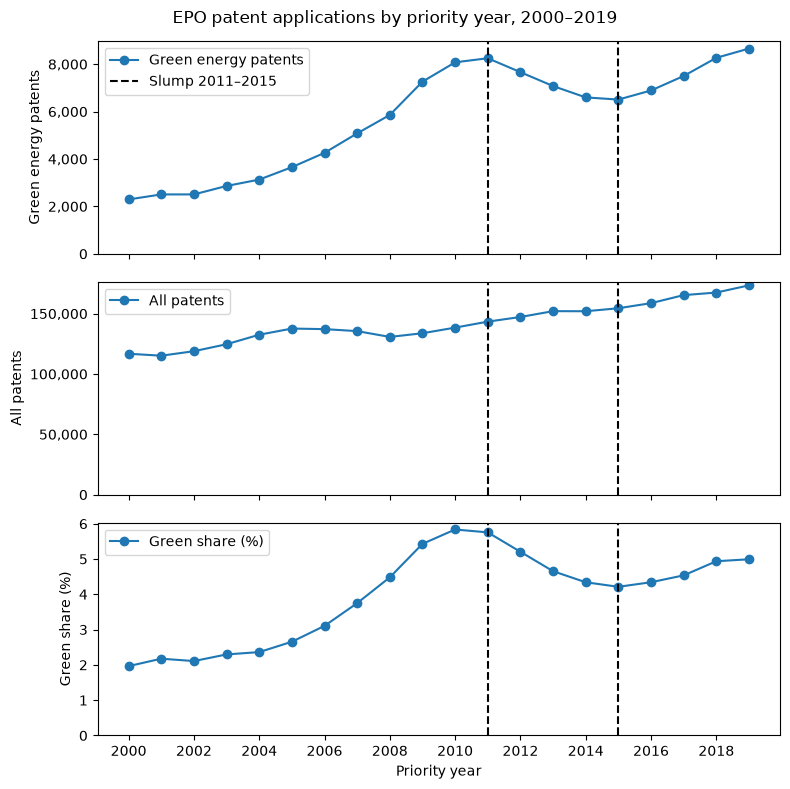

In [12]:
# One panel per column of by_year: column name -> label for axis and legend
panels = {
    'green': 'Green energy patents',
    'total': 'All patents',
    'share': 'Green share (%)',
}

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 8))

# zip() pairs each panel (ax) with one (column, label) item of the dict, so
# one loop draws all three panels in the same way. strict=True raises an error
# if the number of panels and dict items differ, instead of dropping one.
for ax, (column, label) in zip(axes, panels.items(), strict=True):
    ax.plot(by_year.index, by_year[column], marker='o', label=label)
    # Dashed black lines at the slump's start and end. The slump is labelled
    # in the top panel's legend only, so the same entry is not repeated three
    # times (a label of None leaves a line out of the legend)
    slump_label = f'Slump {slump_start}–{slump_end}' if ax is axes[0] else None
    ax.axvline(slump_start, color='black', ls='--', label=slump_label)
    ax.axvline(slump_end, color='black', ls='--')
    ax.set_ylabel(label)
    # Start the y-axis at zero so changes are not visually exaggerated
    ax.set_ylim(bottom=0)
    # Thousands separators on the y-axis (150,000 instead of 150000):
    # set_major_formatter() formats every tick label with this f-string pattern
    ax.yaxis.set_major_formatter('{x:,.0f}')
    # loc='best' lets matplotlib place each legend where it covers the least data
    ax.legend(loc='best')

# The panels share one x-axis, so it is labelled on the bottom panel only
axes[-1].set_xlabel('Priority year')
# Whole years as ticks (every second year) instead of 2002.5, 2007.5, ...
axes[-1].set_xticks(by_year.index[::2])
fig.suptitle('EPO patent applications by priority year, 2000–2019')
fig.tight_layout()

### Answers

1. **Development.** Green energy patenting grew strongly from 2000 to 2011: from 2,295 patents in 2000 to a peak of 8,251 in 2011, about 3.6 times as many. Its share of all patents in the sample rose from 1.97 % to 5.75 % over the same years. By 2019 the count (8,660) is about 5 % above the 2011 peak.

2. **Slump.** Yes. Measured from peak to trough (the dashed lines in the figure), the slump starts in 2011 and ends in 2015: green patents fell every year from the 2011 peak to a trough of 6,508 in 2015 (−21 %), and recovered from 2016. Measured as a share, the decline starts a year earlier: the share peaked at 5.84 % in 2010 and fell to 4.21 % in 2015.

3. **Green-specific or general?** The slump is specific to green energy. During the slump, all patents rose overall (143,392 → 154,489, +8 %) while green patents fell. The reverse happened in 2005–2008, when all patents dipped but green patents kept growing. Since the peak, green patenting has also not kept pace with patenting in general: from 2011 to 2019 all patents grew by about 21 %, green patents by only about 5 %, so the green share (4.99 % in 2019) is still below its peak. The green share in the bottom panel adjusts for this general growth in patenting, and it falls during the slump as well, from 5.75 % in 2011 to 4.21 % in 2015. Tasks 3 and 4 show which technologies drove the boom and the slump.

***
## Task 3: How has the technology mix changed?

### Patents per period and main group

We take the main-group rows of `categories` (one row per patent and main group), split the sample years into five-year periods and count the patents in each main group.
A patent with several codes in the same main group counts once there; a patent in several main groups counts once in each.
Periods are labelled by their first year (2000 = 2000–2004).

In [13]:
# Period length in years: the exam uses four five-year periods
PERIOD_YEARS = 5

# Table 1 rows of categories: one row per (patent, main group), so two codes
# in the same group count once, while a patent in two groups counts once in
# each. rename() gives the column the name used in the tables below.
group_rows = categories.loc[categories['category'].isin(MAIN_GROUPS.values())]
group_rows = group_rows.rename(columns={'category': 'main_group'})

# First year of each row's period, e.g. 2007 -> 2005 and 2014 -> 2010.
# A separate Series, so no extra column is added; .rename('period') gives
# the Series a name, which becomes the name of the period index below
period = (
    FIRST_YEAR + (group_rows['prio_year'] - FIRST_YEAR) // PERIOD_YEARS * PERIOD_YEARS
).rename('period')

# Patents per (period, main group): one row per patent and group, so .size()
# counts each patent once per group
counts = group_rows.groupby([period, 'main_group']).size()

# Main groups in Table 1 order (the dict keeps the order of Table 1), since
# unstack() would sort them alphabetically
GROUP_ORDER = list(MAIN_GROUPS.values())

# Long -> wide for display: one row per period, one column per main group
counts.unstack('main_group')[GROUP_ORDER]

main_group,Renewable energy,Efficient combustion,Nuclear energy,Efficient power transmission,Non-fossil fuels,Storage and hydrogen,Other energy conversion
period,,,,,,,
2000,3136,705,499,287,764,8243,106
2005,10676,1279,738,475,2554,11180,356
2010,15080,1691,1145,875,2910,17426,604
2015,11797,934,1063,903,1792,22478,559


### Shares of the main groups per period

Each main group's count as a percentage of all main-group counts in the same period.
Since a patent in several main groups appears in several counts, we divide by the sum of the counts, so every period adds up to 100 %.

In [14]:
# transform('sum') gives every row the total of its period, so each count can
# be divided by its own period's total ('period' is the index level name)
period_total = counts.groupby('period').transform('sum')
shares = (counts / period_total * 100).unstack('main_group')[GROUP_ORDER]

# Check: the shares of every period add up to 100
print(f'Sum of shares per period: {shares.sum(axis=1).round(1).to_list()}')
shares.round(1)

Sum of shares per period: [100.0, 100.0, 100.0, 100.0]


main_group,Renewable energy,Efficient combustion,Nuclear energy,Efficient power transmission,Non-fossil fuels,Storage and hydrogen,Other energy conversion
period,,,,,,,
2000,22.8,5.1,3.6,2.1,5.6,60.0,0.8
2005,39.2,4.7,2.7,1.7,9.4,41.0,1.3
2010,38.0,4.3,2.9,2.2,7.3,43.9,1.5
2015,29.8,2.4,2.7,2.3,4.5,56.9,1.4


### Figure: technology mix per period

One stacked bar per period; each bar is split into the main groups' shares and adds up to 100 %.

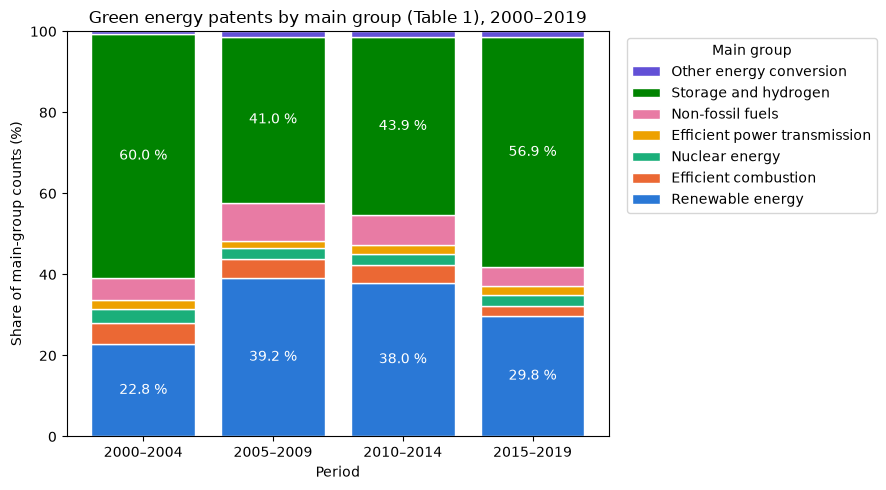

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

# Full period labels for the x-axis, e.g. 2005 -> '2005–2009'
labels = [f'{start}–{start + PERIOD_YEARS - 1}' for start in shares.index]

# Stacked bars: bottom= is where each segment starts. It begins at 0 and
# grows by each group's shares, so the next group sits on top of the last one.
# Each group's colour is looked up by its label in COLORS; the white edges
# separate the segments.
# Segments of at least LABEL_MIN % get their share written inside, so the
# two dominant groups can be read without looking them up in the table
LABEL_MIN = 10

bottom = 0
for group in shares.columns:
    bars = ax.bar(
        labels,
        shares[group],
        bottom=bottom,
        label=group,
        color=COLORS[group],
        edgecolor='white',
    )
    # bar_label() writes one text per bar; label_type='center' puts it in the
    # middle of the segment. Small segments get an empty label.
    ax.bar_label(
        bars,
        labels=[
            f'{share:.1f} %' if share >= LABEL_MIN else '' for share in shares[group]
        ],
        label_type='center',
        color='white',
    )
    bottom = bottom + shares[group]

ax.set_xlabel('Period')
ax.set_ylabel('Share of main-group counts (%)')
ax.set_ylim(0, 100)
ax.set_title('Green energy patents by main group (Table 1), 2000–2019')

# The bars fill the whole plot, so the legend goes outside on the right:
# bbox_to_anchor=(1.02, 1) puts its upper-left corner just right of the plot.
# reverse=True lists the groups top-down, in the same order as the stack.
ax.legend(title='Main group', bbox_to_anchor=(1.02, 1), loc='upper left', reverse=True)
fig.tight_layout()

### Answers

1. **Which groups make up most of green patenting?** Two main groups dominate green energy patenting: Storage and hydrogen and Renewable energy. Together they account for 80–87 % of the patent counts in every period, and Storage and hydrogen is the largest group in all four periods.

2. **How has the mix changed, and how does this relate to the slump?** Renewable energy was the main driver of the boom from 2000–04 to 2005–09: its share increased from 22.8 % to 39.2 %, while its patent count more than tripled (3,136 → 10,676). Non-fossil fuels also increased its share, from 5.6 % to 9.4 %. However, the trend reversed in 2015–19. The share of Renewable energy declined to 29.8 %, and its patent count fell by 22 % compared with 2010–14. Non-fossil fuels and Efficient combustion experienced even steeper declines in counts (−38 % and −45 %). In contrast, Storage and hydrogen continued to grow (+29 %), increasing its share to 56.9 %.

   This suggests that the slump identified in Task 2 was primarily driven by a decline in energy production technologies, particularly renewables. Storage and hydrogen, on the other hand, continued to expand, cushioning the overall decline: the sum of the counts is almost unchanged between 2010–14 and 2015–19 (39,731 → 39,526). The periods do not line up exactly with the slump, since 2010–14 contains the 2011 peak and most of the decline, and 2015–19 contains the 2015 trough and the recovery. The period comparison therefore shows the slump only roughly; Task 4 follows the renewable technologies year by year, including whether they recovered after 2015.

***
## Task 4: Wind versus solar

### Renewable energy patents per year and technology

We take the technology rows of `categories` (one row per patent and technology) and count the patents per priority year in each renewable energy technology (Table 2).
A patent with several codes in the same technology counts once there; a patent in several technologies counts once in each.
Codes without a technology (`Y02E 10/0…` and the other main groups) have no technology row, so they are left out.

In [16]:
# Table 2 rows of categories: one row per (patent, technology). Only main
# group 10 codes with a Table 2 digit have such a row. rename() gives the
# column the name used in the tables below.
tech_rows = categories.loc[categories['category'].isin(TECHNOLOGIES.values())]
tech_rows = tech_rows.rename(columns={'category': 'technology'})

# Patents per (year, technology): one row per patent and technology, so
# .size() counts each patent once per technology
yearly = tech_rows.groupby(['prio_year', 'technology']).size()

# Long -> wide: one row per year, one column per technology
yearly = yearly.unstack('technology')
yearly

technology,Other renewables,Solar,Wind
prio_year,,,
2000,34,306,116
2001,52,334,182
2002,54,328,151
2003,74,467,222
2004,109,548,244
2005,94,726,279
2006,145,949,386
2007,206,1304,530
2008,278,1832,776


### Peak and last year per technology

For each technology: the year with the most patents, the number of patents in that year and in the last sample year, and the percentage change between the two.

In [17]:
# Column name for the last sample year, built from the constant
last_col = f'patents_{LAST_YEAR}'

# One row per technology: idxmax() gives the year of the largest count in each
# column, max() the count itself, and .loc[LAST_YEAR] the row of the last year
peaks = pd.DataFrame(
    {
        'peak_year': yearly.idxmax(),
        'peak_patents': yearly.max(),
        last_col: yearly.loc[LAST_YEAR],
    }
)

# Change from the peak year to the last year in percent (negative = decline)
peaks['change_pct'] = (
    (peaks[last_col] - peaks['peak_patents']) / peaks['peak_patents'] * 100
).round(1)

# Largest peak first
peaks = peaks.sort_values('peak_patents', ascending=False)
peaks

,peak_year,peak_patents,patents_2019,change_pct
technology,,,,
Solar,2010,2323,1093,-52.9
Wind,2011,1188,1024,-13.8
Other renewables,2011,296,172,-41.9


### Figure: renewable energy patents by technology

One line per technology; each peak is marked with a point and labelled with its year.

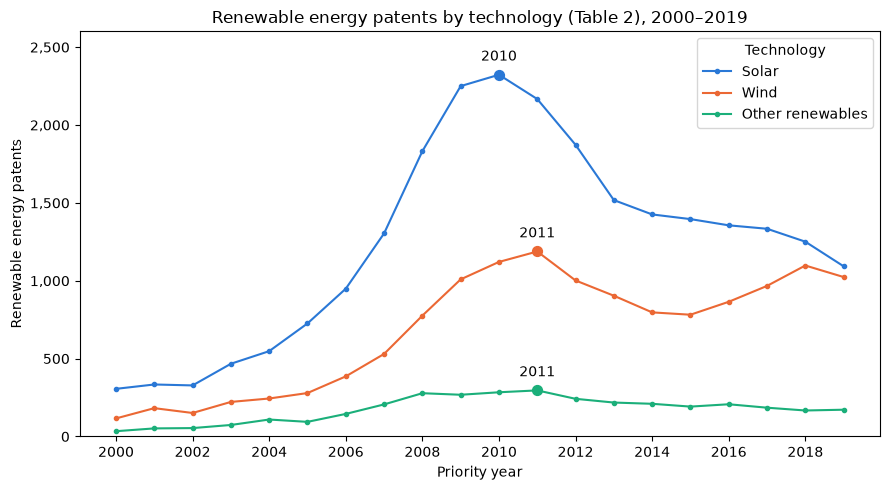

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))

# Space between a peak point and its year label: 3 % of the highest count,
# so the label sits just above the point whatever the scale
offset = 0.03 * yearly.max().max()

# One line per technology, in peak-table order so the legend follows the
# table; colours are looked up by name in TECH_COLORS
for tech in peaks.index:
    # Small markers show that the line joins yearly counts (as in Task 2)
    ax.plot(
        yearly.index,
        yearly[tech],
        color=TECH_COLORS[tech],
        marker='o',
        ms=3,
        label=tech,
    )

    # Peak: a point on top of the line (zorder=3) and the year above it
    year = peaks.loc[tech, 'peak_year']
    count = peaks.loc[tech, 'peak_patents']
    ax.scatter(year, count, color=TECH_COLORS[tech], s=50, zorder=3)
    ax.text(year, count + offset, f'{year}', ha='center', va='bottom')

ax.set_xlabel('Priority year')
ax.set_ylabel('Renewable energy patents')
ax.set_title('Renewable energy patents by technology (Table 2), 2000–2019')
# Whole years as ticks, as in Task 2
ax.set_xticks(yearly.index[::2])
# Room above the highest peak for its label
ax.set_ylim(0, yearly.max().max() * 1.12)
# Thousands separators on the y-axis (2,000 instead of 2000), as in Task 2
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.legend(title='Technology')
fig.tight_layout()

### Answers

Solar and Other renewables collapsed after their peaks and did not recover; Wind also fell sharply but recovered most of its loss.

**Solar.** Solar patenting peaked at 2,323 in 2010, followed by a continuous decline through 2019, reaching 1,093 (−52.9 %). The steepest decline occurred between 2011 and 2013. By 2019, patent counts had returned to levels comparable to 2006–2007, suggesting no meaningful recovery.

**Wind.** Wind patenting peaked at 1,188 in 2011 before declining to 782 in 2015 (−34 %). It subsequently rebounded to 1,098 in 2018, reaching 92 % of its peak, before falling slightly to 1,024 in 2019 (−13.8 % from peak). Among the three categories, wind is the only one showing a substantial recovery.

**Other renewables.** Patenting peaked at 296 in 2011 and fell to 172 (−41.9 %). The peak is not sharp, however: the count stayed between 268 and 296 from 2008 to 2011, so 2011 is the top of a plateau rather than a single peak year. Since 2014, activity has remained relatively flat at 167–210 patents annually, with no clear sign of recovery.

**Link to Tasks 2 and 3.** Between 2015 and 2019, total green patenting increased by 2,152, from 6,508 to 8,660. However, Solar declined by 303 patents, Wind increased by 242, and Other renewables declined by 20. This indicates that renewables overall did not drive the recovery in green patenting. Instead, the recovery is consistent with the continued growth of Storage and hydrogen identified in Task 3, suggesting that the shift in innovation was increasingly toward energy storage rather than energy production technologies.

***
## Task 5: Who drives green energy innovation?

We use fractional counting: each patent is split between its applicants by `app_share`, so a country's or applicant's number of patents is the sum of `app_share` over its rows.

### Applicants of green patents

Only applicants of green energy patents are needed in Task 5, so we filter `applicants` once before the function.

In [19]:
# Only applicants of green energy patents are needed in this task. Filtering
# once here keeps the merge inside top_n() small: 126,097 rows instead of
# 3,059,537 (printed below)
green_applicants = applicants.loc[applicants['appln_id'].isin(categories['appln_id'])]
print(f'green_applicants: {len(green_applicants):,} rows (of {len(applicants):,})')

green_applicants: 126,097 rows (of 3,059,537)


### Function: top n countries or applicants

`top_n()` selects the patents in one category (any label from Table 1 or Table 2) and period, adds their applicants, and sums `app_share` per country or applicant.
The tables it uses are passed in as arguments, so the function does not depend on variables outside it.

In [20]:
def top_n(categories, applicants, category, by, start=FIRST_YEAR, end=LAST_YEAR, n=10):
    """
    Return the top n countries or applicants by fractional patent count.

    Parameters
    ----------
    categories : pandas.DataFrame
        One row per (patent, category), with columns ``appln_id``,
        ``prio_year`` and ``category``.
    applicants : pandas.DataFrame
        One row per (patent, applicant), with columns ``appln_id``,
        ``app_name``, ``ctry_code`` and ``app_share``.
    category : str
        Category label from Table 1 or Table 2, e.g. 'Storage and hydrogen'
        or 'Wind'.
    by : str
        What to rank: 'country' or 'applicant'.
    start, end : int, optional
        First and last priority year of the period.
    n : int or None, optional
        Number of countries or applicants to return. None returns all.

    Returns
    -------
    pandas.Series
        Fractional patent counts indexed by country code or applicant name,
        largest first.

    Examples
    --------
    >>> top_n(categories, green_applicants, 'Wind', 'country', 2010, 2014, n=5)
    """
    # The exam's words for the two rankings -> the column that holds them
    columns = {'country': 'ctry_code', 'applicant': 'app_name'}

    # Patents in the category and period. categories has one row per
    # (patent, category), so each patent's shares are added only once.
    mask = (
        (categories['category'] == category)
        & (categories['prio_year'] >= start)
        & (categories['prio_year'] <= end)
    )
    selected = categories.loc[mask, ['appln_id']]

    # Inner join: keep the applicants of the selected patents only
    # (patents without an applicant have no shares to add)
    rows = pd.merge(selected, applicants, on='appln_id', how='inner')

    # Fractional counting: sum app_share per country or applicant
    result = rows.groupby(columns[by])['app_share'].sum()
    return result.sort_values(ascending=False).head(n)

### Check of the fractional counting

Summed over all countries, the shares should give back the number of patents in the category and period.

In [21]:
# The category and the two periods of Figure 1, defined once and reused below.
# MAIN_GROUPS['10'] is the Table 1 label 'Renewable energy'.
renewable = MAIN_GROUPS['10']
periods = [(2005, 2009), (2015, 2019)]

# All countries per period (n=None), computed once and reused for this check,
# for Figure 1 (top 10) and for the country shares after Figure 1. Summed over
# all countries, the shares should equal the period's number of patents from
# the Task 3 counts (same five-year periods), apart from the few patents
# without applicants or with shares that don't add up to 1.
all_countries = [
    top_n(categories, green_applicants, renewable, 'country', start, end, n=None)
    for start, end in periods
]
for (start, end), result in zip(periods, all_countries, strict=True):
    n_patents = counts.loc[(start, renewable)]
    print(f'{start}–{end}: {n_patents:,} patents, shares sum to {result.sum():,.1f}')

2005–2009: 10,676 patents, shares sum to 10,676.0
2015–2019: 11,797 patents, shares sum to 11,796.0


### Plot function

Both figures have two panels of horizontal bars, so one plotting function draws them.

In [22]:
def plot_top(results, titles, suptitle, colors, sharex=False, max_len=36):
    """
    Plot top-n results from top_n() as horizontal bar panels side by side.

    Parameters
    ----------
    results : list of pandas.Series
        One result from top_n() per panel.
    titles : list of str
        Title of each panel.
    suptitle : str
        Title of the whole figure.
    colors : list of str
        Bar colour of each panel, looked up by label in COLORS or TECH_COLORS
        by the caller.
    sharex : bool, optional
        Use the same x-axis scale in all panels.
    max_len : int, optional
        Labels longer than this are cut at the last whole word and end with
        '…', so long applicant names don't squash the bars. The results
        themselves keep the full names.
    """
    fig, axes = plt.subplots(1, len(results), figsize=(13, 4.5), sharex=sharex)

    # strict=True: raise an error if the lists have different lengths
    for ax, result, title, color in zip(axes, results, titles, colors, strict=True):
        # barh draws the first bar at the bottom, so reverse the order
        # (.iloc[::-1] steps through the rows backwards) to put the largest on top
        result = result.iloc[::-1]

        # Long names are cut at the last whole word: name[:max_len] keeps the
        # first max_len characters, and .rsplit(' ', 1)[0] drops the part
        # after the last space, so no word is cut in the middle
        labels = [
            name if len(name) <= max_len else name[:max_len].rsplit(' ', 1)[0] + '…'
            for name in result.index
        ]

        # Bars at positions 0, 1, 2, ... with the names as tick labels, so two
        # names that are identical after cutting still get separate bars
        positions = range(len(result))
        ax.barh(positions, result.to_numpy(), color=color)
        ax.set_yticks(positions, labels=labels)
        ax.set_title(title)
        ax.set_xlabel('Patents (fractional count)')
        # Thousands separators (2,000 instead of 2000), as in Tasks 2 and 4
        ax.xaxis.set_major_formatter('{x:,.0f}')
        ax.grid(axis='x', alpha=0.2)
        ax.set_axisbelow(True)

    fig.suptitle(suptitle)
    fig.tight_layout()

### Figure 1: top countries in renewable energy, 2005–2009 and 2015–2019

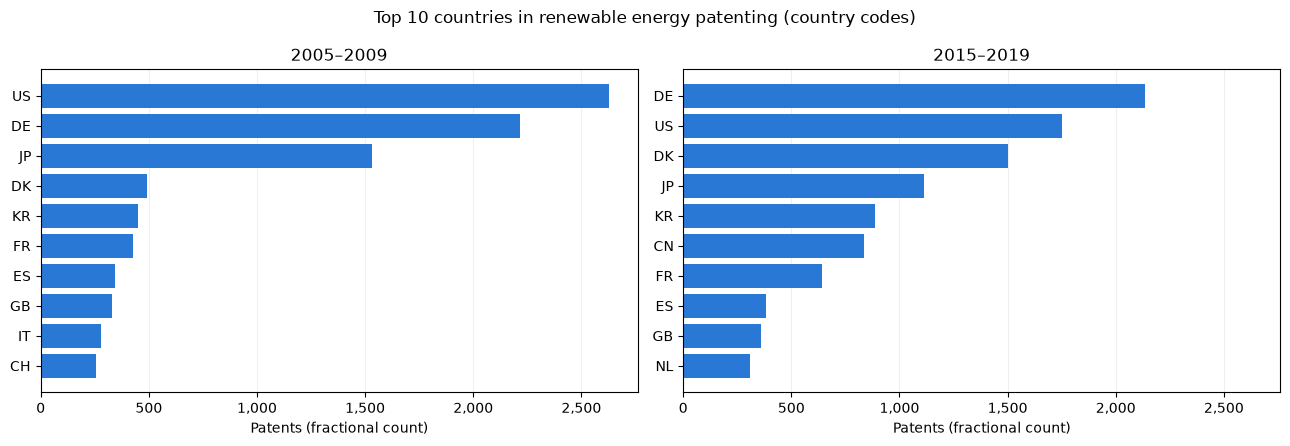

In [23]:
# Figure 1: the top 10 of each period, taken from all_countries (already
# sorted, largest first) instead of running top_n() again. The same x-scale
# (sharex=True) makes the two periods comparable, and both panels use the
# colour of Renewable energy, as in Task 3.
country_results = [result.head(10) for result in all_countries]
plot_top(
    country_results,
    [f'{start}–{end}' for start, end in periods],
    'Top 10 countries in renewable energy patenting (country codes)',
    colors=[COLORS[renewable]] * len(periods),
    sharex=True,
)

### Country shares of renewable energy patents

The number of renewable energy patents differs between the two periods, so the counts in Figure 1 also move with the total.
We therefore also express each country's count as a percentage of all renewable energy patents in the period.

In [24]:
# Each country's share (%) of all renewable energy patents in its period.
# result.sum() is the period's total (the check above), so shares add to 100
country_shares = pd.DataFrame(
    {
        f'{start}–{end}': result / result.sum() * 100
        for (start, end), result in zip(periods, all_countries, strict=True)
    }
)

# Keep the countries shown in Figure 1 (top 10 in either period).
# .union() combines the two lists of country codes without duplicates
in_figure = country_results[0].index.union(country_results[1].index)
country_shares = country_shares.loc[in_figure].sort_values(
    country_shares.columns[-1], ascending=False
)
country_shares.round(1)

,2005–2009,2015–2019
ctry_code,,
DE,20.8,18.1
US,24.6,14.8
DK,4.6,12.7
JP,14.3,9.4
KR,4.2,7.5
CN,1.1,7.1
FR,4.0,5.5
ES,3.2,3.2
GB,3.1,3.0


### Applicants in solar and wind, 2000–2019

We rank all applicants in solar and in wind over the whole sample period once.
Figure 2 shows the top 10 of each, and the top 10's share of all patents in the technology shows how concentrated it is.

In [25]:
# All applicants per technology over the whole sample period (n=None),
# computed once and reused for the concentration below and for Figure 2
technologies = ['Solar', 'Wind']
all_applicants = [
    top_n(categories, green_applicants, technology, 'applicant', n=None)
    for technology in technologies
]

# Concentration: the top 10 applicants' share of all patents in the technology
for technology, result in zip(technologies, all_applicants, strict=True):
    top10 = result.head(10).sum()
    total = result.sum()
    print(
        f'{technology:<6} top 10: {top10:>6,.0f} of {total:>6,.0f} patents '
        f'({top10 / total * 100:.1f} %)'
    )

Solar  top 10:  2,969 of 24,778 patents (12.0 %)


Wind   top 10:  5,908 of 13,634 patents (43.3 %)


### Figure 2: top applicants in solar and wind, 2000–2019

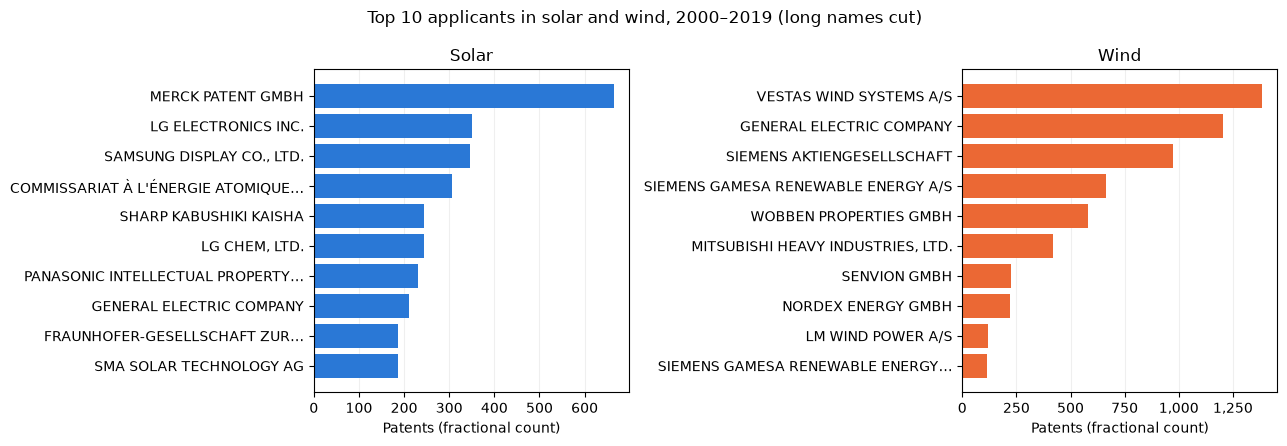

In [26]:
# Figure 2: the top 10 of each technology, taken from all_applicants instead
# of running top_n() again. Separate x-scales: wind's top applicants have
# about twice as many patents as solar's, so a shared scale would squash the
# solar panel. Solar and Wind keep their Task 4 colours.
applicant_results = [result.head(10) for result in all_applicants]
plot_top(
    applicant_results,
    technologies,
    f'Top 10 applicants in solar and wind, {FIRST_YEAR}–{LAST_YEAR} (long names cut)',
    colors=[TECH_COLORS[technology] for technology in technologies],
)

### Top applicants in renewable energy per period

To see whether applicants explain the country changes in Figure 1, we use the same function for applicants in each period.

In [27]:
# Do the applicants explain the country changes? The top 10 applicants in
# renewable energy in each period of Figure 1, side by side by rank.
# reset_index() turns the names into a column; keys= labels the two periods
top_applicants = pd.concat(
    [
        top_n(categories, green_applicants, renewable, 'applicant', start, end)
        .round(0)
        .reset_index()
        for start, end in periods
    ],
    axis=1,
    keys=[f'{start}–{end}' for start, end in periods],
)

# Rank 1 = largest, instead of the default 0
top_applicants.index = top_applicants.index + 1
top_applicants

2005–2009            \
                                             app_name app_share   
1                            GENERAL ELECTRIC COMPANY     492.0   
2                             VESTAS WIND SYSTEMS A/S     317.0   
3                          SIEMENS AKTIENGESELLSCHAFT     204.0   
4                              SHARP KABUSHIKI KAISHA     150.0   
5                   MITSUBISHI HEAVY INDUSTRIES, LTD.     142.0   
6                                   MERCK PATENT GMBH     130.0   
7                E. I. DU PONT DE NEMOURS AND COMPANY      88.0   
8                            SANYO ELECTRIC CO., LTD.      86.0   
9   FRAUNHOFER-GESELLSCHAFT ZUR FÖRDERUNG DER ANGE...      85.0   
10                                LG ELECTRONICS INC.      83.0   

                                            2015–2019            
                                             app_name app_share  
1                             VESTAS WIND SYSTEMS A/S     589.0  
2                 SIEMENS GAMESA RENEWABLE ENERGY A/S     584.0  
3                            GENERAL ELECTRIC COMPANY     341.0  
4                              WOBBEN PROPERTIES GMBH     333.0  
5                           SAMSUNG DISPLAY CO., LTD.     277.0  
6                                   MERCK PATENT GMBH     170.0  
7                          SIEMENS AKTIENGESELLSCHAFT     132.0  
8                                 LG ELECTRONICS INC.     123.0  
9   COMMISSARIAT À L'ÉNERGIE ATOMIQUE ET AUX ÉNERG...      97.0  
10           GENERAL ELECTRIC RENOVABLES ESPAÑA, S.L.      95.0

### Applicants in Korea and China

Korea and China both gained share in renewable energy, but only Korean applicants appear in the top 10 above.
Passing only one country's applicant rows to `top_n()` shows how each country's patents are spread over its own applicants.

In [28]:
# Passing only one country's applicant rows to top_n() ranks that country's
# own applicants (n=None: all of them). A high top-10 share means a few large
# applicants; a low share means many small ones.
for country in ['KR', 'CN']:
    country_rows = green_applicants.loc[green_applicants['ctry_code'] == country]
    for start, end in periods:
        result = top_n(
            categories, country_rows, renewable, 'applicant', start, end, n=None
        )
        top10_share = result.head(10).sum() / result.sum() * 100
        print(
            f'{country} {start}–{end}: {result.sum():>4,.0f} patents, '
            f'{len(result):>3} applicants, top 10 hold {top10_share:4.1f} %, '
            f'largest: {result.index[0]} ({result.iloc[0]:,.0f})'
        )

KR 2005–2009:  451 patents, 103 applicants, top 10 hold 71.1 %, largest: LG ELECTRONICS INC. (83)
KR 2015–2019:  886 patents, 136 applicants, top 10 hold 81.0 %, largest: SAMSUNG DISPLAY CO., LTD. (277)
CN 2005–2009:  113 patents,  78 applicants, top 10 hold 41.4 %, largest: BYD COMPANY LIMITED (12)
CN 2015–2019:  836 patents, 265 applicants, top 10 hold 42.8 %, largest: BEIJING GOLDWIND SCIENCE & CREATION WINDPOWER EQUIPMENT CO., LTD. (63)


### Answers

1. **Which countries lead, and how has this changed?** In 2005–2009 applicants from the US had the largest number of renewable energy patents (about 2,600), followed by Germany (about 2,200) and Japan (about 1,500). There is a big fall down to Denmark in 4th place (about 500). In 2015–2019 Germany has overtaken the US, and Denmark has moved ahead of Japan: the US fell to about 1,750 and Japan to about 1,100, while Denmark tripled to about 1,500. The gap between 3rd and 4th place therefore narrowed, from about 1,000 to about 400 patents. China entered the top 10 in 6th place (about 840), and the Netherlands also came in, while Italy and Switzerland dropped out. Measured as a share of all renewable energy patents in the period (the table after Figure 1), the US fell from 24.6 % to 14.8 % and Japan from 14.3 % to 9.4 %, while Denmark rose from 4.6 % to 12.7 % and China from 1.1 % to 7.1 %. Germany became the largest country even though its share fell slightly (20.8 % → 18.1 %), because the US fell much more. Since the data are applications at the European Patent Office, European applicants are likely over-represented: US, Japanese and Chinese firms may file many inventions only in their home patent offices, so the ranking describes patenting in Europe rather than a world ranking.

2. **Which organisations dominate solar and wind?** In solar the largest applicant by far is Merck Patent GmbH, a German chemicals and materials company, with about 665 patents, almost twice as many as LG Electronics in second place (about 350). Besides Merck, there is a large presence of electronics and technology conglomerates (LG, Samsung, Sharp, Panasonic), another materials company (LG Chem) and public research institutes (CEA in France, Fraunhofer in Germany). In wind we see mostly specialised turbine makers (Vestas, Siemens Gamesa, Wobben, Senvion, Nordex) and a few large industrial groups (General Electric, Siemens, Mitsubishi Heavy Industries). Wind also has a higher concentration of patents at the top: the top ten applicants account for 43.3 % of all wind patents (5,908 of 13,634 fractional patents), compared with 12.0 % for solar (2,969 of 24,778).

3. **Do the applicants help explain the changes among countries?** The top applicants come from the countries that lead Figure 1: Germany (Merck, SMA, Siemens, Wobben), South Korea (LG, Samsung), Japan (Panasonic, Sharp), the US (General Electric) and Denmark (Vestas). This is likely one reason why these five countries are the top 5 in both periods. The top applicants per period show that a few applicants explain much of the change. Denmark's rise comes from Vestas (317 → 589) and Siemens Gamesa Renewable Energy A/S (584 in 2015–2019, not in the 2005–2009 top 10), while Siemens AG in Germany fell from 204 to 132, so Siemens' wind patenting appears to have moved from a German to a Danish applicant. General Electric fell from 492 to 341, which is part of the US decline. Korea's rise (451 → 886 patents, 4.2 % → 7.5 %) is driven by a few large electronics groups: Samsung Display (277 in 2015–2019, not in the 2005–2009 top 10) and LG Electronics (83 → 123) are in the top 10, and the ten largest Korean applicants hold 81.0 % of Korea's patents. China's rise (113 → 836 patents, 1.1 % → 7.1 %) instead comes from many smaller applicants: 265 Chinese applicants in 2015–2019 (78 in 2005–2009), of which the largest, Goldwind, has only 63 patents and the ten largest together hold 42.8 %. That is why no Chinese applicant is in the top 10. We should mention that Figure 2 covers the whole period 2000–2019 and only solar and wind, while the country figure covers all renewable energy, so Figure 2 alone cannot show changes between the periods; the table of top applicants per period is needed for that.

***
## Task 6: Use of online resources

Throughout the term paper we mostly used generative AI (Claude in the desktop app and Claude Code in VS Code) rather than other online sources. We used it from the start for planning: Claude read the exam text and the course material with us, helped us split the work into one stage per task, and pointed out important aspects and common mistakes, e.g. counting a patent twice in the same category. When we noticed that Namibia's country code («NA») was read as a missing value, Claude helped us fix it.

We solved one task at a time. For each task Claude proposed an approach, which we approved or changed, and we made sure we understood every part of the code by answering check questions about each cell in our own words. AI was especially helpful in making the code more efficient, by avoiding repeated work and unnecessary computations.

Code suggested by claude that is not in the syllabus:
- Task 1: the three reading functions, including reading the CPC and applicant files in chunks (`read_green()`, `read_applicants()`) and the `keep_default_na=False, na_values=['']` fix for Namibia; the `categories` table is based on a first version written by one of us.
- Figures: the colour dicts, `set_major_formatter()` for thousands separators, and the legend placement with `bbox_to_anchor`.
- After a final review: smaller data types when reading (`dtype=`, `astype('category')`), and cutting long applicant names at a whole word in `plot_top()` (`.rsplit()`).

We checked every cell against the three checkpoints and against totals from earlier tasks (e.g. yearly counts add up to the Task 1 totals, shares add up to 100 %), re-ran the notebook from a fresh kernel, and made sure we could explain every line. AI was also a good way of uncovering gaps in our knowledge, and a tool for troubleshooting, which ensured that the notebook runs in one go without errors.

We did not copy code from Stack Overflow or other online sources. The answers to the questions are our own writing. At our request, Claude checked them for accuracy, corrected some numbers, and drafted a few sentences that we checked against the output before keeping them (sentences with supporting numbers in Tasks 4 and 5).